Backend: d:\AIHMRSV1\AIMHRA\backend
Dataset: d:\AIHMRSV1\AIMHRA\backend\data\Mathernal_Risk.csv
Dataset exists: True
Dataset shape: (6057, 8)

XGBOOST
Model: d:\AIHMRSV1\AIMHRA\backend\ml_artifacts\xgboost_full.joblib
Model exists: True
Classes: ['low risk', 'mid risk', 'high risk']

FEATURES FROM constants.py:
['age', 'body_temperature', 'heart_rate', 'systolic_bp', 'diastolic_bp', 'bmi', 'hba1c', 'fasting_glucose']

FEATURES STORED IN MODEL:
['age', 'body_temperature', 'heart_rate', 'systolic_bp', 'diastolic_bp', 'bmi', 'hba1c', 'fasting_glucose']

SHAP array shape: (300, 8, 3)

Generating LOW RISK plot...


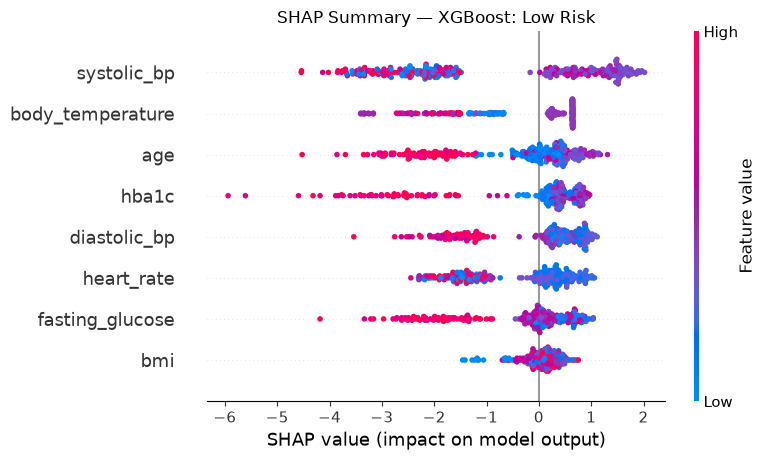


Generating MID RISK plot...


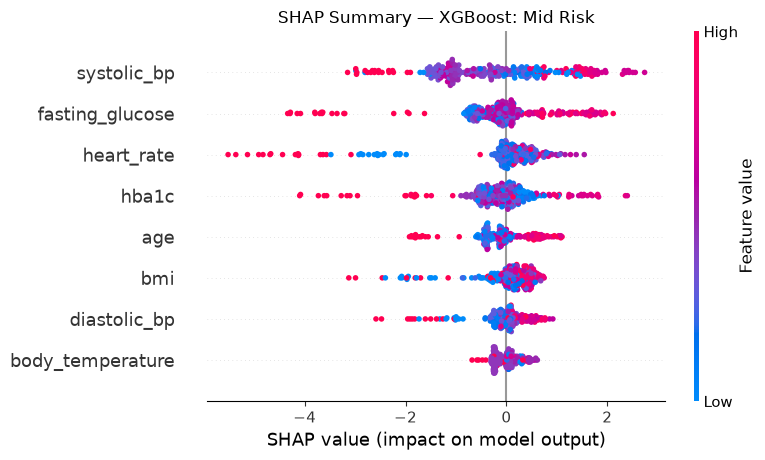


Generating HIGH RISK plot...


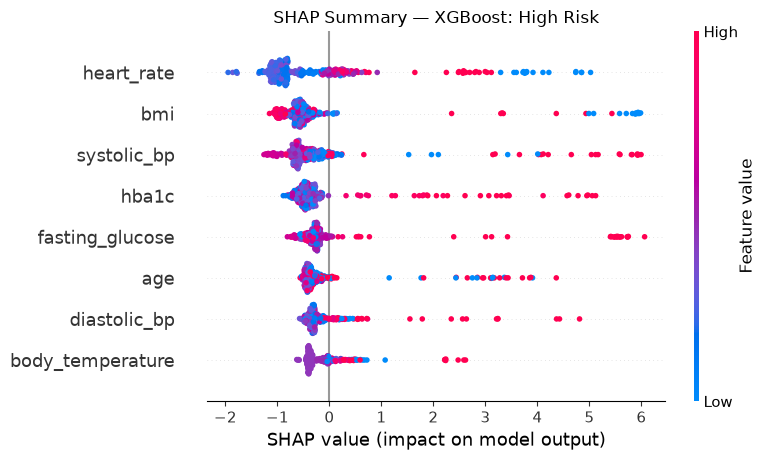


RANDOM FOREST
Model: d:\AIHMRSV1\AIMHRA\backend\ml_artifacts\randomforest_full.joblib
Model exists: True
Classes: ['low risk', 'mid risk', 'high risk']

FEATURES FROM constants.py:
['age', 'body_temperature', 'heart_rate', 'systolic_bp', 'diastolic_bp', 'bmi', 'hba1c', 'fasting_glucose']

FEATURES STORED IN MODEL:
['age', 'body_temperature', 'heart_rate', 'systolic_bp', 'diastolic_bp', 'bmi', 'hba1c', 'fasting_glucose']

SHAP array shape: (300, 8, 3)

Generating LOW RISK plot...


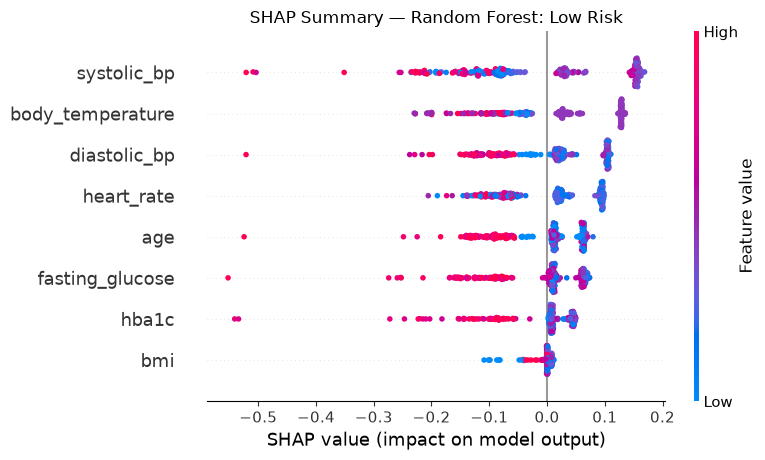


Generating MID RISK plot...


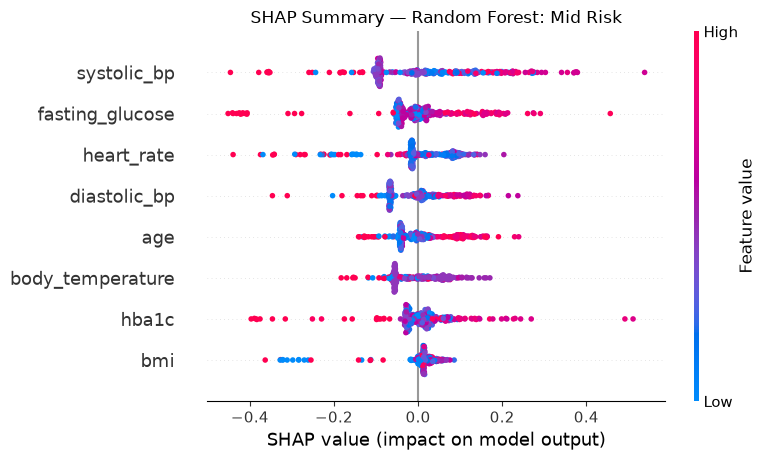


Generating HIGH RISK plot...


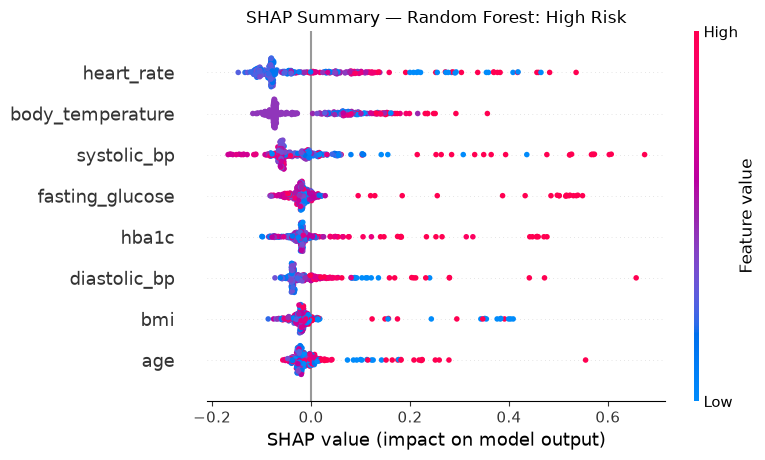

In [10]:
# ============================================================
# SHAP SUMMARY PLOTS — XGBoost + Random Forest
# LOW / MID / HIGH RISK
# ============================================================

import sys
import pathlib
import warnings
import numpy as np
import joblib
import shap
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. Backend directory
# ------------------------------------------------------------
BACKEND = pathlib.Path.cwd()

if str(BACKEND) not in sys.path:
    sys.path.insert(0, str(BACKEND))

print("Backend:", BACKEND)

# ------------------------------------------------------------
# 2. Import project modules
# ------------------------------------------------------------
from mlcore.constants import FEATURES
from mlcore.dataset import clean_dataset, load_raw_dataset
from mlcore.preprocessing import Preprocessor

# ------------------------------------------------------------
# 3. Load dataset
# ------------------------------------------------------------
DATA = BACKEND / "data" / "Mathernal_Risk.csv"

print("Dataset:", DATA)
print("Dataset exists:", DATA.exists())

df, _ = clean_dataset(load_raw_dataset(DATA))

X_full = df[FEATURES].to_numpy(dtype=np.float64)

print("Dataset shape:", X_full.shape)

# ------------------------------------------------------------
# 4. Select up to 300 samples
# ------------------------------------------------------------
rng = np.random.default_rng(42)

n = min(300, len(X_full))

idx = rng.choice(
    len(X_full),
    size=n,
    replace=False
)

X_sample_raw = X_full[idx]

# ------------------------------------------------------------
# 5. Function to generate SHAP plots
# ------------------------------------------------------------
def generate_shap_plots(model_filename, model_name):

    print("\n" + "=" * 60)
    print(model_name.upper())
    print("=" * 60)

    # Load trained model
    MODEL_PATH = BACKEND / "ml_artifacts" / model_filename

    print("Model:", MODEL_PATH)
    print("Model exists:", MODEL_PATH.exists())

    b = joblib.load(MODEL_PATH)

    # Load preprocessing information saved with model
    pre = Preprocessor.from_dict(b["preprocessor"])

    classes = list(b["classes"])

    print("Classes:", classes)

    print("\nFEATURES FROM constants.py:")
    print(FEATURES)

    print("\nFEATURES STORED IN MODEL:")
    print(b["features"])

    # Transform samples using the SAME preprocessing
    # that was used during model training
    X_sample = pre.transform(X_sample_raw)

    # Create SHAP explainer
    explainer = shap.TreeExplainer(b["model"])

    # Calculate SHAP values
    sv = np.asarray(
        explainer.shap_values(X_sample)
    )

    print("\nSHAP array shape:", sv.shape)

    # --------------------------------------------------------
    # Generate Low, Mid and High risk plots
    # --------------------------------------------------------
    for risk in ["low risk", "mid risk", "high risk"]:

        risk_idx = classes.index(risk)

        # Handle multiclass SHAP output
        if sv.ndim == 3:
            sv_class = sv[:, :, risk_idx]
        else:
            sv_class = sv

        print(f"\nGenerating {risk.upper()} plot...")

        plt.figure()

        shap.summary_plot(
            sv_class,
            X_sample,
            feature_names=b["features"],
            show=False
        )

        plt.title(
            f"SHAP Summary — {model_name}: {risk.title()}",
            fontsize=12
        )

        plt.tight_layout()
        plt.show()


# ------------------------------------------------------------
# 6. XGBoost — Low / Mid / High
# ------------------------------------------------------------
generate_shap_plots(
    "xgboost_full.joblib",
    "XGBoost"
)

# ------------------------------------------------------------
# 7. Random Forest — Low / Mid / High
# ------------------------------------------------------------
generate_shap_plots(
    "randomforest_full.joblib",
    "Random Forest"
)


XGBOOST
Model: d:\AIHMRSV1\AIMHRA\backend\ml_artifacts\xgboost_full.joblib
Model exists: True

Feature Importance:
body_temperature: 0.2511
systolic_bp: 0.1882
heart_rate: 0.1168
diastolic_bp: 0.1156
fasting_glucose: 0.1012
hba1c: 0.0964
age: 0.0828
bmi: 0.0480


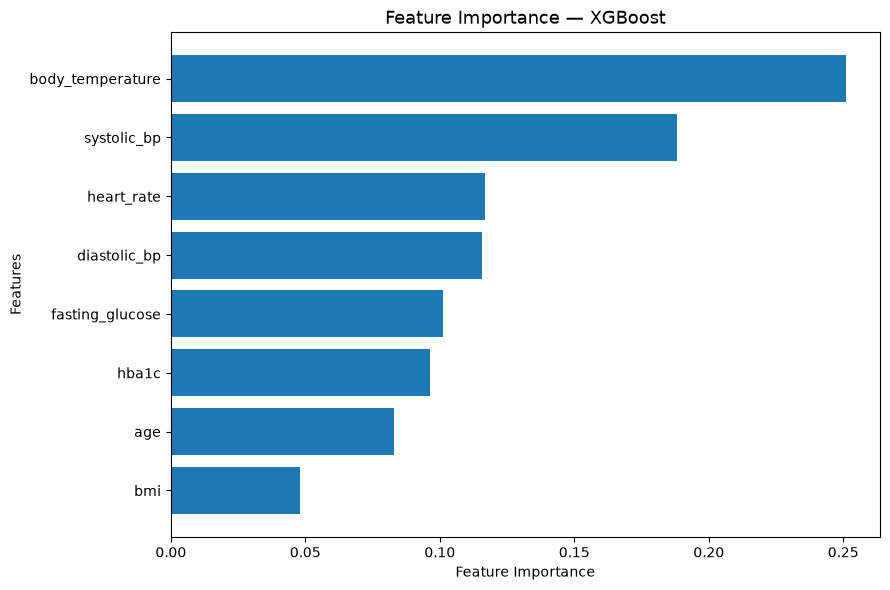


RANDOM FOREST
Model: d:\AIHMRSV1\AIMHRA\backend\ml_artifacts\randomforest_full.joblib
Model exists: True

Feature Importance:
systolic_bp: 0.2345
heart_rate: 0.1588
body_temperature: 0.1452
diastolic_bp: 0.1149
fasting_glucose: 0.1085
hba1c: 0.0896
age: 0.0880
bmi: 0.0604


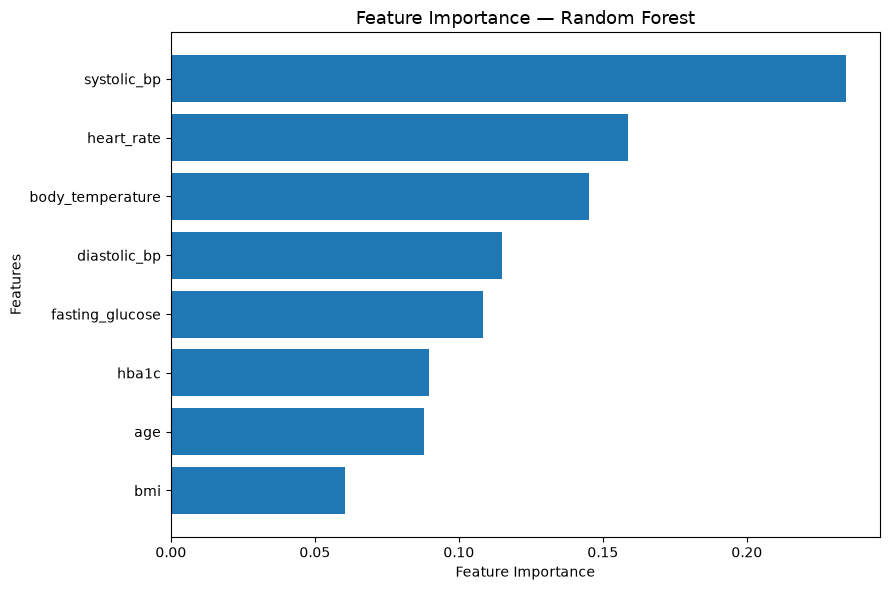

In [11]:
# ============================================================
# FEATURE IMPORTANCE — XGBoost + Random Forest
# ============================================================

import pathlib
import joblib
import numpy as np
import matplotlib.pyplot as plt

BACKEND = pathlib.Path.cwd()

# ------------------------------------------------------------
# Function to create feature importance plot
# ------------------------------------------------------------
def plot_feature_importance(model_filename, model_name):

    MODEL_PATH = BACKEND / "ml_artifacts" / model_filename

    print("\n" + "=" * 60)
    print(model_name.upper())
    print("=" * 60)

    print("Model:", MODEL_PATH)
    print("Model exists:", MODEL_PATH.exists())

    # Load trained model
    b = joblib.load(MODEL_PATH)

    model = b["model"]
    features = b["features"]

    # Get feature importance
    importance = model.feature_importances_

    # Sort from most important to least important
    sorted_idx = np.argsort(importance)

    sorted_features = np.array(features)[sorted_idx]
    sorted_importance = importance[sorted_idx]

    print("\nFeature Importance:")
    for feature, value in zip(
        sorted_features[::-1],
        sorted_importance[::-1]
    ):
        print(f"{feature}: {value:.4f}")

    # --------------------------------------------------------
    # Plot
    # --------------------------------------------------------
    plt.figure(figsize=(9, 6))

    plt.barh(
        sorted_features,
        sorted_importance
    )

    plt.xlabel("Feature Importance")
    plt.ylabel("Features")
    plt.title(
        f"Feature Importance — {model_name}",
        fontsize=13
    )

    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# XGBoost
# ------------------------------------------------------------
plot_feature_importance(
    "xgboost_full.joblib",
    "XGBoost"
)

# ------------------------------------------------------------
# Random Forest
# ------------------------------------------------------------
plot_feature_importance(
    "randomforest_full.joblib",
    "Random Forest"
)

In [2]:
# ============================================================
# SHAP RELATIVE IMPORTANCE (%) — ONE TABLE PER MODEL
# Low / Mid / High Risk
# ============================================================

import sys
import pathlib
import warnings
import numpy as np
import joblib
import shap
import pandas as pd

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. Backend directory
# ------------------------------------------------------------
BACKEND = pathlib.Path.cwd()

if str(BACKEND) not in sys.path:
    sys.path.insert(0, str(BACKEND))

print("Backend:", BACKEND)

# ------------------------------------------------------------
# 2. Project modules
# ------------------------------------------------------------
from mlcore.constants import FEATURES
from mlcore.dataset import clean_dataset, load_raw_dataset
from mlcore.preprocessing import Preprocessor

# ------------------------------------------------------------
# 3. Load dataset
# ------------------------------------------------------------
DATA = BACKEND / "data" / "Mathernal_Risk.csv"

df, _ = clean_dataset(load_raw_dataset(DATA))

X_full = df[FEATURES].to_numpy(dtype=np.float64)

print("Dataset shape:", X_full.shape)

# ------------------------------------------------------------
# 4. Same 300 samples used for SHAP plots
# ------------------------------------------------------------
rng = np.random.default_rng(42)

n = min(300, len(X_full))

idx = rng.choice(
    len(X_full),
    size=n,
    replace=False
)

X_sample_raw = X_full[idx]


# ============================================================
# 5. Generate ONE combined table for each model
# ============================================================

def generate_shap_percentage_table(model_filename, model_name):

    print("\n" + "=" * 80)
    print(model_name.upper())
    print("=" * 80)

    # --------------------------------------------------------
    # Load model
    # --------------------------------------------------------
    MODEL_PATH = BACKEND / "ml_artifacts" / model_filename

    b = joblib.load(MODEL_PATH)

    # --------------------------------------------------------
    # Load preprocessing
    # --------------------------------------------------------
    pre = Preprocessor.from_dict(
        b["preprocessor"]
    )

    classes = list(b["classes"])

    # --------------------------------------------------------
    # Transform samples
    # --------------------------------------------------------
    X_sample = pre.transform(
        X_sample_raw
    )

    # --------------------------------------------------------
    # SHAP explainer
    # --------------------------------------------------------
    explainer = shap.TreeExplainer(
        b["model"]
    )

    sv = np.asarray(
        explainer.shap_values(X_sample)
    )

    print("SHAP array shape:", sv.shape)

    # --------------------------------------------------------
    # Calculate importance for each class
    # --------------------------------------------------------

    importance = {}

    for risk in ["low risk", "mid risk", "high risk"]:

        risk_idx = classes.index(risk)

        # Multiclass SHAP
        if sv.ndim == 3:
            sv_class = sv[:, :, risk_idx]
        else:
            sv_class = sv

        # Mean absolute SHAP
        mean_abs_shap = np.mean(
            np.abs(sv_class),
            axis=0
        )

        # Convert to percentage
        percentage = (
            mean_abs_shap /
            np.sum(mean_abs_shap)
        ) * 100

        importance[risk] = percentage

    # --------------------------------------------------------
    # Create ONE table
    # --------------------------------------------------------

    table = pd.DataFrame({
        "Feature": b["features"],
        "Low Risk (%)": importance["low risk"],
        "Mid Risk (%)": importance["mid risk"],
        "High Risk (%)": importance["high risk"]
    })

    # --------------------------------------------------------
    # Sort by overall average importance
    #
    # This keeps one consistent feature order while still
    # showing the individual percentage for each class.
    # --------------------------------------------------------

    table["Overall"] = table[
        ["Low Risk (%)", "Mid Risk (%)", "High Risk (%)"]
    ].mean(axis=1)

    table = table.sort_values(
        "Overall",
        ascending=False
    )

    table = table.drop(
        columns=["Overall"]
    ).reset_index(drop=True)

    # --------------------------------------------------------
    # Round values
    # --------------------------------------------------------

    table[
        ["Low Risk (%)", "Mid Risk (%)", "High Risk (%)"]
    ] = table[
        ["Low Risk (%)", "Mid Risk (%)", "High Risk (%)"]
    ].round(2)

    # --------------------------------------------------------
    # Add total row
    # --------------------------------------------------------

    total_row = pd.DataFrame({
        "Feature": ["TOTAL"],
        "Low Risk (%)": [
            table["Low Risk (%)"].sum()
        ],
        "Mid Risk (%)": [
            table["Mid Risk (%)"].sum()
        ],
        "High Risk (%)": [
            table["High Risk (%)"].sum()
        ]
    })

    table = pd.concat(
        [table, total_row],
        ignore_index=True
    )

    # --------------------------------------------------------
    # Print final table
    # --------------------------------------------------------

    print("\n")
    print(
        table.to_string(
            index=False
        )
    )

    return table


# ============================================================
# 6. XGBoost — ONE TABLE
# ============================================================

xgb_table = generate_shap_percentage_table(
    "xgboost_full.joblib",
    "XGBoost"
)


# ============================================================
# 7. Random Forest — ONE TABLE
# ============================================================

rf_table = generate_shap_percentage_table(
    "randomforest_full.joblib",
    "Random Forest"
)

Backend: d:\AIHMRSV1\AIMHRA\backend
Dataset shape: (6057, 8)

XGBOOST
SHAP array shape: (300, 8, 3)


         Feature  Low Risk (%)  Mid Risk (%)  High Risk (%)
     systolic_bp     24.930000     25.200001      15.400000
      heart_rate     11.430000     14.970000      19.030001
           hba1c     12.160000     12.860000      12.940000
 fasting_glucose      9.880000     16.320000      11.650000
             age     13.010000      9.540000      10.610000
             bmi      3.380000      9.310000      16.320000
    diastolic_bp     11.460000      7.330000       7.670000
body_temperature     13.740000      4.470000       6.380000
           TOTAL     99.990005    100.000008     100.000000

RANDOM FOREST
SHAP array shape: (300, 8, 3)


         Feature  Low Risk (%)  Mid Risk (%)  High Risk (%)
     systolic_bp         24.08         23.39          16.53
      heart_rate         13.71         13.00          22.03
body_temperature         16.95         10.30          17.68
 fasting_gl

In [3]:
# ============================================================
# SHAP IMPORTANCE (%) — SIMPLE TABLES
# XGBoost + Random Forest
# Based on 300 samples
# ============================================================

import sys
import pathlib
import warnings
import numpy as np
import joblib
import shap
import pandas as pd

warnings.filterwarnings("ignore")

# Backend
BACKEND = pathlib.Path.cwd()

if str(BACKEND) not in sys.path:
    sys.path.insert(0, str(BACKEND))

# Project modules
from mlcore.constants import FEATURES
from mlcore.dataset import clean_dataset, load_raw_dataset
from mlcore.preprocessing import Preprocessor

# Dataset
DATA = BACKEND / "data" / "Mathernal_Risk.csv"

df, _ = clean_dataset(load_raw_dataset(DATA))

X_full = df[FEATURES].to_numpy(dtype=np.float64)

# ------------------------------------------------------------
# Same 300 samples used in your SHAP summary plots
# ------------------------------------------------------------
rng = np.random.default_rng(42)

n = min(300, len(X_full))

idx = rng.choice(
    len(X_full),
    size=n,
    replace=False
)

X_sample_raw = X_full[idx]


# ============================================================
# Function
# ============================================================

def get_percentage_table(model_filename):

    MODEL_PATH = BACKEND / "ml_artifacts" / model_filename

    b = joblib.load(MODEL_PATH)

    pre = Preprocessor.from_dict(
        b["preprocessor"]
    )

    classes = list(b["classes"])

    # Same preprocessing
    X_sample = pre.transform(X_sample_raw)

    # SHAP
    explainer = shap.TreeExplainer(b["model"])

    sv = np.asarray(
        explainer.shap_values(X_sample)
    )

    results = {}

    # --------------------------------------------------------
    # Calculate percentage for each risk class
    # --------------------------------------------------------

    for risk in ["low risk", "mid risk", "high risk"]:

        risk_idx = classes.index(risk)

        if sv.ndim == 3:
            sv_class = sv[:, :, risk_idx]
        else:
            sv_class = sv

        # Mean absolute SHAP
        mean_abs_shap = np.mean(
            np.abs(sv_class),
            axis=0
        )

        # Percentage
        percentage = (
            mean_abs_shap /
            np.sum(mean_abs_shap)
        ) * 100

        results[risk] = percentage

    # --------------------------------------------------------
    # Create table
    # --------------------------------------------------------

    table = pd.DataFrame({
        "Feature": b["features"],
        "Low Risk": results["low risk"],
        "Mid Risk": results["mid risk"],
        "High Risk": results["high risk"]
    })

    # Round to 2 decimal places
    table[
        ["Low Risk", "Mid Risk", "High Risk"]
    ] = table[
        ["Low Risk", "Mid Risk", "High Risk"]
    ].round(2)

    return table


# ============================================================
# XGBoost
# ============================================================

xgb_table = get_percentage_table(
    "xgboost_full.joblib"
)

print("\nXGBOOST — SHAP IMPORTANCE (%)")
print(xgb_table.to_string(index=False))


# ============================================================
# Random Forest
# ============================================================

rf_table = get_percentage_table(
    "randomforest_full.joblib"
)

print("\nRANDOM FOREST — SHAP IMPORTANCE (%)")
print(rf_table.to_string(index=False))


XGBOOST — SHAP IMPORTANCE (%)
         Feature  Low Risk  Mid Risk  High Risk
             age     13.01  9.540000  10.610000
body_temperature     13.74  4.470000   6.380000
      heart_rate     11.43 14.970000  19.030001
     systolic_bp     24.93 25.200001  15.400000
    diastolic_bp     11.46  7.330000   7.670000
             bmi      3.38  9.310000  16.320000
           hba1c     12.16 12.860000  12.940000
 fasting_glucose      9.88 16.320000  11.650000

RANDOM FOREST — SHAP IMPORTANCE (%)
         Feature  Low Risk  Mid Risk  High Risk
             age     11.02     10.46       6.97
body_temperature     16.95     10.30      17.68
      heart_rate     13.71     13.00      22.03
     systolic_bp     24.08     23.39      16.53
    diastolic_bp     14.27     11.63       8.95
             bmi      1.33      6.49       8.15
           hba1c      8.06     10.30       9.43
 fasting_glucose     10.58     14.44      10.25
